# 750 € a Month, Nothing Else: the ETF or a Nürnberger Basisrente

One sum, two places to put it, from January 2026 until October 2063, and not
a euro invested beyond it. In world **A** you never sign anything with an
insurer: 750 € a month go into a broad ETF. In world **B** you sign a
fondsgebundene Basisrente for 750 € a month — the tariff of the contract you
actually hold, NÜRNBERGER NFX3208T, with its costs and its annuity factors.
The contract you really signed in 2024, at 500 € a month, is in neither
world: this is the product question at 750 €, asked from a clean slate.

Everything else the household earns is lived on, in both worlds alike: the
engine's cash account takes whatever the month leaves and nothing in it
counts as wealth. There is no other capital on day one. The one thing that
differs is what happens to the tax the contract saves, which comes back every
July. World **B** spends it, like the rest of the month's money, so both
worlds invest exactly 750 € a month. World **B+** invests it in the ETF the
month it arrives — the same money out of pocket as A, more money in
instruments — and is kept here because it is the only way to see what the
deduction is worth.

At 67 world A holds an ETF, world B a pension for life and world B+ both a
pension and a smaller ETF. Section 4 asks the question a pension raises:
if A paid itself, out of its ETF, exactly the extra net income B's pension
brings, how long would A's ETF last?

Everything is shown in **today's euros**: the engine runs in nominal terms
with 2% inflation, and every figure is deflated back to 2026. The market
returns are real ones — a 6% market here is 6% above inflation. `AMOUNT` is
a parameter; nothing else needs touching for another sum. Model results
under stated assumptions, not advice: they move with the market return, the
tax rate in old age and how long one lives.

In [1]:
from dataclasses import dataclass
from pathlib import Path
import sys

ROOT_DIR = Path.cwd().resolve().parent
sys.path.append(str(ROOT_DIR))

import pandas as pd
from matplotlib import pyplot as plt

from src.model import (
    Earner,
    Etf,
    FinancialModel,
    GermanHousehold,
    PrivateHealthInsurance,
    Retirement,
    RuerupAnnuity,
    RuerupCosts,
    RuerupPension,
)
from src.model.german_tax import RENTENWERT, TaxSystem, basisrente_cap, social_contributions

## Assumptions

**You, alone.** 100,000 € gross (the 2026 payslips), HanseMerkur private
insurance, Steuerklasse I, no children. The salary follows wages at 3.3% a
year nominal. You work from 27 to 67 without a gap at the contribution
ceiling, so the statutory pension is 80 Entgeltpunkte: 3,263 € a month at
today's Rentenwert, and it keeps exactly its purchasing power from here on
(indexed with inflation, not with wages). Retirement from November 2063, at
67: you keep the private insurance with the pension fund's subsidy, nothing
is withheld from the pensions, and the Finanzamt asks for each year's tax in
advance from the second retired year on. Whatever a month leaves after the
750 € is spent — the salary's surplus while you work, the pensions after —
and so is the July settlement of the income tax, in every world.

**The contract.** 750 € a month for 454 months, 340,500 € in all, at the
tariff's own costs: 2.5% of the contribution sum (8,513 €) spread over the
first five years, 4.5% of every contribution, 0.40% a year on the value; the
funds cost 0.38% a year on top. At Rentenbeginn the value becomes a pension
at the guaranteed Rentenfaktor of 21.246830 € per 10,000 € — the only figure
the insurer promises — or at its 2024 basis of 24.996271 € plus a 1.87%
Zusatzrente, nearly twice as much and not promised. The pension is flat in
nominal euros, so in today's money it shrinks 2% a year.

**The deduction.** Contributions are deducted within the §10 Abs. 3 cap:
30,826 € in 2026 for one person, less both halves of the statutory pension
contribution, 12,226 € — the 9,000 € a year fit entirely, and the cap grows
with the contribution ceiling. The saving arrives with the next July's
refund: spent in B, invested in B+.

**The ETF.** A broad world ETF at 0.20% TER, taxed at 26.375% on 70% of the
gain on every sale (Teilfreistellung), 18.46% of the gain. In A it takes
750 € a month until October 2063 and nothing after; in B+ it takes each
July's refund. Both products see the same market: 6% a year above inflation
in the base case, 3%, 4% and 8% alongside.

**The calendar.** The engine's first year is 2026, the year its tax law is
enacted for; the tariff borders drift by inertia for the whole seventy years,
the 45% border included.

In [2]:
SYSTEM = TaxSystem(rich_threshold_frozen=False)
INFLATION = 0.02
WAGE_GROWTH = SYSTEM.yearly_wage_growth

AMOUNT = 750.0                      # the sum in question, a month

# --- you, alone ---------------------------------------------------------------
GROSS = 100_000.0
HANSEMERKUR = PrivateHealthInsurance(
    monthly_premium=638.0, monthly_care_premium=57.0, deductible_share=349.0 / 638.0, monthly_rebate=182.95
)
WORKING_MONTHS = 454                # January 2026 – October 2063
POINTS = 2.0 * 40                   # 27 to 67 at the ceiling: 80 Entgeltpunkte
PENSION_INDEXATION = INFLATION      # the statutory pension keeps its purchasing power, no more
YEARS = 71                          # to December 2096
AT_67 = 38                          # the year-38 row is December 2063
START_AGE = 67 - AT_67

# --- the contract ---------------------------------------------------------------
GUARANTEED = RuerupAnnuity()                                   # 21.246830 € per 10,000 €
DECLARED = RuerupAnnuity(factor=24.996271, bonus_rate=0.0187)  # 2024 basis, not promised
FUND_COSTS = 0.0038

# --- the market, above inflation ----------------------------------------------
REAL_MARKET = 0.06
REAL_MARKETS = (0.03, 0.04, 0.06, 0.08)
ETF_TER = 0.0020
ETF_TAX = 0.26375 * 0.7


def nominal(real: float) -> float:
    return (1.0 + real) * (1.0 + INFLATION) - 1.0


MARKET = nominal(REAL_MARKET)

room = basisrente_cap(SYSTEM, joint=False)
room -= 2.0 * social_contributions(GROSS, SYSTEM, n_children=0, private_health=True).pension
print(f"Statutory pension at today's Rentenwert: €{POINTS * RENTENWERT:,.0f} a month")
print(f"Deduction room in 2026: €{room:,.0f} a year, €{room / 12:,.0f} a month; the contract needs €{12 * AMOUNT:,.0f}")
print(f"A {REAL_MARKET:.0%} real market is {MARKET:.2%} nominal in the engine")

Statutory pension at today's Rentenwert: €3,263 a month
Deduction room in 2026: €12,226 a year, €1,019 a month; the contract needs €9,000
A 6% real market is 8.12% nominal in the engine


In [3]:
def fund_return(market: float, costs: float) -> float:
    return (1.0 + market) * (1.0 - costs) - 1.0


def household() -> GermanHousehold:
    return GermanHousehold(
        earners=(
            Earner(
                monthly_gross=GROSS / 12,
                yearly_increase_rate=WAGE_GROWTH,
                private_health=HANSEMERKUR,
                retirement=Retirement.from_entgeltpunkte(
                    POINTS, working_months=WORKING_MONTHS, yearly_increase_rate=PENSION_INDEXATION
                ),
            ),
        ),
        joint=False,
        tax=SYSTEM,
    )


def basisrente(market: float, annuity: RuerupAnnuity = DECLARED) -> RuerupPension:
    return RuerupPension(
        monthly_contribution=AMOUNT,
        contribution_months=WORKING_MONTHS,
        yearly_return_rate=fund_return(market, FUND_COSTS),
        annuity=annuity,
        name="ruerup",
    )


@dataclass(frozen=True)
class ScheduledEtf(Etf):
    # An ETF fed by a fixed schedule of monthly amounts and nothing else:
    # `schedule[m]` is what it takes in model month m (0-based).
    schedule: tuple = ()

    def claim(self, state, ctx):
        index = (ctx.year - 1) * 12 + ctx.month - 1
        return self.schedule[index] if index < len(self.schedule) else 0.0


def every_month(amount: float, months: int) -> tuple:
    return tuple(amount if month < months else 0.0 for month in range(YEARS * 12))


def every_july(amounts: dict) -> tuple:
    schedule = [0.0] * (YEARS * 12)
    for year, amount in amounts.items():
        schedule[(year - 1) * 12 + 6] = amount
    return tuple(schedule)


def etf(market: float, schedule: tuple, name: str = "etf") -> ScheduledEtf:
    return ScheduledEtf(
        yearly_return_rate=fund_return(market, ETF_TER), tax_rate=ETF_TAX,
        monthly_investment=0.0, schedule=schedule, name=name,
    )


def run(*portfolios, market: float) -> pd.DataFrame:
    # The cash account is the sink: it takes what the month leaves and is
    # spent, so it never counts as wealth. Nothing is invested on day one.
    parts = [household(), Etf.cash(name="cash"), *portfolios]
    model = FinancialModel(parts, years=YEARS, start_age=START_AGE, yearly_inflation_rate=INFLATION)
    frame = model.run().set_index("year")
    assert not (frame["cash.capital"] < 0).any(), "the cash account went negative at a year end"
    return frame


def worlds_at(market: float, annuity: RuerupAnnuity = DECLARED) -> dict:
    a = run(etf(market, every_month(AMOUNT, WORKING_MONTHS)), market=market)
    b = run(basisrente(market, annuity), market=market)
    # The contract's refunds: the July settlements B receives beyond A's, in the working years.
    refunds = {
        year: max(float(b.loc[year, "household.yearly_refund_received"] - a.loc[year, "household.yearly_refund_received"]), 0.0)
        for year in range(2, AT_67 + 2)
    }
    b_plus = run(basisrente(market, annuity), etf(market, every_july(refunds), name="refund_etf"), market=market)
    return {"A": a, "B": b, "B+": b_plus, "refunds": refunds}


def todays(amount: float, year: int) -> float:
    return amount / (1.0 + INFLATION) ** year


def eur(amount: float) -> str:
    return f"€{amount:,.0f}"


def td(amount: float, year: int) -> str:
    return eur(todays(amount, year))


def age(value) -> str:
    return "after 100" if value is None else f"{value:.0f}"


def pensions_net(frame: pd.DataFrame, year: int) -> float:
    # The month's pensions after premiums and the year's income tax, a month.
    pension = frame["ruerup.monthly_pension"][year] if "ruerup.monthly_pension" in frame else 0.0
    return frame.loc[year, "household.monthly_amount"] + pension - frame.loc[year, "household.yearly_assessed_tax"] / 12.0


def after_tax(frame: pd.DataFrame, name: str, year: int) -> float:
    return frame[f"{name}.capital_after_tax"][year] if f"{name}.capital_after_tax" in frame else 0.0

## 1. What 750 € a Month Buys

The contract on its own, from the terms alone: what the 340,500 € paid in
become at 67 across market returns, and the pension they convert into, in
today's euros. For scale, the last column is the same 750 € a month
compounded in the ETF at its own net return, before any tax and before the
refunds the contract earns.

In [4]:
rows = []
for real in (0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08):
    market = nominal(real)
    capital = basisrente(market).capital_at_pension_start()
    monthly = (1.0 + fund_return(market, ETF_TER)) ** (1.0 / 12.0) - 1.0
    plain = 0.0
    for _ in range(WORKING_MONTHS):
        plain = plain * (1.0 + monthly) + AMOUNT
    rows.append(
        {
            "market return, real": f"{real:.0%}",
            "capital at 67 (capital)": td(capital, AT_67),
            "pension, guaranteed, a month": td(GUARANTEED.monthly_pension(capital), AT_67),
            "pension, 2024 basis, a month": td(DECLARED.monthly_pension(capital), AT_67),
            "the same money in the ETF, gross (capital)": td(plain, AT_67),
        }
    )
pd.DataFrame(rows).set_index("market return, real")

,capital at 67 (capital),"pension, guaranteed, a month","pension, 2024 basis, a month","the same money in the ETF, gross (capital)"
"market return, real",,,,
2%,"€284,894",€605,"€1,156","€354,472"
3%,"€355,277",€755,"€1,442","€446,833"
4%,"€446,430",€949,"€1,812","€567,419"
5%,"€564,839","€1,200","€2,292","€725,275"
6%,"€719,047","€1,528","€2,918","€932,372"
7%,"€920,302","€1,955","€3,735","€1,204,545"
8%,"€1,183,410","€2,514","€4,802","€1,562,730"


Where the gap to the gross ETF figure comes from, at the base market return,
one cost layer at a time. Each figure is what that layer takes from the
capital at 67, compounded, in today's euros.

In [5]:
def capital_with(costs: RuerupCosts, fund_costs: float) -> float:
    return RuerupPension(
        monthly_contribution=AMOUNT,
        contribution_months=WORKING_MONTHS,
        yearly_return_rate=fund_return(MARKET, fund_costs),
        costs=costs,
    ).capital_at_pension_start()


steps = [
    ("no costs at all", capital_with(RuerupCosts(0.0, 60, 0.0, 0.0), 0.0)),
    ("+ 2.5% acquisition cost, over five years", capital_with(RuerupCosts(0.025, 60, 0.0, 0.0), 0.0)),
    ("+ 4.5% of every contribution", capital_with(RuerupCosts(0.025, 60, 0.045, 0.0), 0.0)),
    ("+ 0.40% a year on the value", capital_with(RuerupCosts(), 0.0)),
    ("+ the funds' own 0.38% a year", capital_with(RuerupCosts(), FUND_COSTS)),
]
pd.DataFrame(
    [
        {
            "": label,
            f"capital at 67, {REAL_MARKET:.0%} real market (capital)": td(value, AT_67),
            "this layer takes (capital)": "" if index == 0 else td(steps[index - 1][1] - value, AT_67),
        }
        for index, (label, value) in enumerate(steps)
    ]
).set_index("")

,"capital at 67, 6% real market (capital)",this layer takes (capital)
,,
no costs at all,"€990,547",
"+ 2.5% acquisition cost, over five years","€926,657","€63,890"
+ 4.5% of every contribution,"€882,083","€44,575"
+ 0.40% a year on the value,"€794,012","€88,070"
+ the funds' own 0.38% a year,"€719,047","€74,965"


## 2. The Three Worlds at 67

The engine's own figures at the end of 2063, in today's euros, at the base
market return. What A's ETF holds, gross and after the tax a sale would cost;
what B's contract converts into a pension; what B+'s ETF made of the refunds.

In [6]:
worlds = worlds_at(MARKET)
guaranteed = worlds_at(MARKET, GUARANTEED)
A, B, B_PLUS, REFUNDS = worlds["A"], worlds["B"], worlds["B+"], worlds["refunds"]

refunds_nominal = sum(REFUNDS.values())
refunds_today = sum(todays(amount, year) for year, amount in REFUNDS.items())
print(f"The contract's refunds: {eur(refunds_nominal)} nominal over {len(REFUNDS)} Julys, {eur(refunds_today)} in today's euros, "
      f"{refunds_nominal / (AMOUNT * WORKING_MONTHS):.0%} of what was paid in; spent in B, invested in B+")
assert B.loc[AT_67, "ruerup.pension_capital"] == B_PLUS.loc[AT_67, "ruerup.pension_capital"]


def etf_block(frame: pd.DataFrame, name: str) -> list:
    gross = frame.loc[AT_67, f"{name}.capital"]
    gain = gross - frame.loc[AT_67, f"{name}.cost_basis"]
    return [gross, gain, gain / gross, gain * ETF_TAX, gross - gain * ETF_TAX]


a_etf, b_etf = etf_block(A, "etf"), etf_block(B_PLUS, "refund_etf")
capital = B.loc[AT_67, "ruerup.pension_capital"]
rows = [
    ("ETF, gross", "capital", td(a_etf[0], AT_67), "", td(b_etf[0], AT_67)),
    ("  of which gain over what was paid in", "capital", td(a_etf[1], AT_67), "", td(b_etf[1], AT_67)),
    ("  gain as a share of the ETF", "%", f"{a_etf[2]:.1%}", "", f"{b_etf[2]:.1%}"),
    ("  tax rate on the gain: 26.375% on 70%", "%", f"{ETF_TAX:.2%}", "", f"{ETF_TAX:.2%}"),
    ("  tax if all of it were sold", "capital", td(-a_etf[3], AT_67), "", td(-b_etf[3], AT_67)),
    ("= ETF after tax", "capital", td(a_etf[4], AT_67), "", td(b_etf[4], AT_67)),
    ("contract capital converted at Rentenbeginn", "capital", "", td(capital, AT_67), td(capital, AT_67)),
    ("  pension, guaranteed", "a month", "", td(GUARANTEED.monthly_pension(capital), AT_67), td(GUARANTEED.monthly_pension(capital), AT_67)),
    ("  pension, 2024 basis", "a month", "", td(DECLARED.monthly_pension(capital), AT_67), td(DECLARED.monthly_pension(capital), AT_67)),
]
pd.DataFrame(rows, columns=["", "unit", "A: ETF", "B: contract, refund spent", "B+: contract, refund invested"]).set_index("")

The contract's refunds: €156,416 nominal over 38 Julys, €107,651 in today's euros, 46% of what was paid in; spent in B, invested in B+


,unit,A: ETF,"B: contract, refund spent","B+: contract, refund invested"
,,,,
"ETF, gross",capital,"€944,268",,"€408,239"
of which gain over what was paid in,capital,"€783,829",,"€334,538"
gain as a share of the ETF,%,83.0%,,81.9%
tax rate on the gain: 26.375% on 70%,%,18.46%,,18.46%
tax if all of it were sold,capital,"€-144,714",,"€-61,764"
= ETF after tax,capital,"€799,554",,"€346,475"
contract capital converted at Rentenbeginn,capital,,"€719,047","€719,047"
"pension, guaranteed",a month,,"€1,528","€1,528"
"pension, 2024 basis",a month,,"€2,918","€2,918"


## 3. The First Year of Retirement

2064, the first year you are retired all year, a month, in today's euros, at
the base market return and the 2024 annuity basis. The statutory pension is
gross; "after premiums" is your cash once the health and care premiums are
paid, the pension fund's subsidy included. The income tax is the assessed tax
on the year, shown as a share of the gross pensions and, for the contract
worlds, as the marginal rate the Basisrente pension is taxed at. The ETF is
shown with what a cautious 3% a year would pay, what 4% would pay, and what
drawing it down to zero by 100 would pay. The unit column says what each row is: a monthly
amount, a capital, or a rate.

In [7]:
YEAR = AT_67 + 1
rate = fund_return(MARKET, ETF_TER)


def drawdown(capital: float) -> float:
    # The level monthly amount that exhausts `capital` in 33 years at the ETF's rate.
    return capital * rate / (1.0 - (1.0 + rate) ** -33) / 12.0


def retirement_table(a: pd.DataFrame, b: pd.DataFrame, b_plus: pd.DataFrame, b_guaranteed: pd.DataFrame) -> pd.DataFrame:
    frames = (a, b, b_plus)
    etfs = (after_tax(a, "etf", YEAR - 1), 0.0, after_tax(b_plus, "refund_etf", YEAR - 1))
    taxes = [frame.loc[YEAR, "household.yearly_assessed_tax"] / 12.0 for frame in frames]
    pensions = [frame["ruerup.monthly_pension"][YEAR] if "ruerup.monthly_pension" in frame else 0.0 for frame in frames]
    nets = [pensions_net(frame, YEAR) for frame in frames]
    gross = [frame.loc[YEAR, "household.monthly_pension"] + pension for frame, pension in zip(frames, pensions)]
    marginal = (taxes[1] - taxes[0]) / pensions[1]

    def money(label, values, unit="a month"):
        return {"": label, "unit": unit, **{column: td(value, YEAR) for column, value in zip(COLUMNS, values)}}

    def rates(label, values):
        return {"": label, "unit": "%", **{column: value for column, value in zip(COLUMNS, values)}}

    rows = [
        money("statutory pension, gross", [frame.loc[YEAR, "household.monthly_pension"] for frame in frames]),
        money("  after health and care premiums", [frame.loc[YEAR, "household.monthly_amount"] for frame in frames]),
        money("Basisrente pension, 2024 basis", pensions),
        money("  the same at the guaranteed factor", [0.0, b_guaranteed.loc[YEAR, "ruerup.monthly_pension"], b_guaranteed.loc[YEAR, "ruerup.monthly_pension"]]),
        money("income tax on all of it", [-tax for tax in taxes]),
        rates("  as a share of the gross pensions", [f"{tax / g:.1%}" for tax, g in zip(taxes, gross)]),
        rates("  marginal rate on the Basisrente pension", ["", f"{marginal:.1%}", f"{marginal:.1%}"]),
        money("= pensions net", nets),
        money("ETF after tax, end of 2063", etfs, "capital"),
        money("  3% a year of it, paid out", [value * 0.03 / 12 for value in etfs]),
        money("  4% a year of it, paid out", [value * 0.04 / 12 for value in etfs]),
        money("  drawn down to zero by 100", [drawdown(value) for value in etfs]),
        money("TOTAL with the 3% withdrawal", [net + value * 0.03 / 12 for net, value in zip(nets, etfs)]),
        money("TOTAL with the 4% withdrawal", [net + value * 0.04 / 12 for net, value in zip(nets, etfs)]),
        money("TOTAL with the drawdown to 100", [net + drawdown(value) for net, value in zip(nets, etfs)]),
    ]
    return pd.DataFrame(rows).set_index("")


COLUMNS = ("A: ETF", "B: contract, refund spent", "B+: contract, refund invested")
retirement_table(A, B, B_PLUS, guaranteed["B"])

,unit,A: ETF,"B: contract, refund spent","B+: contract, refund invested"
,,,,
"statutory pension, gross",a month,"€3,199","€3,199","€3,199"
after health and care premiums,a month,"€2,605","€2,605","€2,605"
"Basisrente pension, 2024 basis",a month,€0,"€2,861","€2,861"
the same at the guaranteed factor,a month,€0,"€1,498","€1,498"
income tax on all of it,a month,€-367,"€-1,300","€-1,300"
as a share of the gross pensions,%,11.5%,21.4%,21.4%
marginal rate on the Basisrente pension,%,,32.6%,32.6%
= pensions net,a month,"€2,238","€4,166","€4,166"
"ETF after tax, end of 2063",capital,"€783,876",€0,"€339,682"


World B, the one that invests 750 € and not a euro more, retires on 4,166 €
a month net: 2,238 € from the statutory pension and 1,928 € from the
contract, after the tax the contract adds at 33 cents on the euro. World A
retires on the same 2,238 € and an ETF of 784,000 €. Drawn at a cautious 3%
that is 1,960 € a month, 4,198 € in all — the same income as B's within
32 €, with the 784,000 € still there and growing. Drawn down to zero by 100
it is 5,620 € a month, 7,858 € in all. B had, in exchange, 37 Julys of
refunds to spend: 156,000 € nominal, 108,000 € in today's money, 242 € a
month on average. World B+, which invested those refunds instead, retires
on the same 4,166 € plus a 340,000 € ETF: 5,015 € a month at 3%, 6,601 €
drawn down — ahead of A at 3%, behind A on the drawdown. At the guaranteed
factor the contract's pension is 1,498 € instead of 2,861 €, and the
comparison is not close.

## 4. If A Paid Itself B's Pension

A pension is income; an ETF is capital. To put them on one scale, let A
sell ETF shares every month from 2064 on and pay itself exactly the extra
net income the contract brings B — the Basisrente pension less the income
tax it adds — flat in nominal euros as the pension is, the gain on each sale
taxed. What is left of A's ETF is then compared with what B and B+ hold
beside their pension: nothing in B, the refund ETF in B+. "Runs out" is the
age at which A's ETF is gone; "falls behind B+" the age at which it is worth
less than B+'s refund ETF.

In [8]:
def pays_itself(a: pd.DataFrame, b: pd.DataFrame, market: float) -> pd.Series:
    # A's ETF after tax at each year end, after paying out B's extra net income every month.
    monthly = (1.0 + fund_return(market, ETF_TER)) ** (1.0 / 12.0) - 1.0
    capital, basis = a.loc[AT_67, "etf.capital"], a.loc[AT_67, "etf.cost_basis"]
    left = {AT_67: capital - max(0.0, capital - basis) * ETF_TAX}
    for year in range(AT_67 + 1, YEARS + 1):
        extra = pensions_net(b, year) - pensions_net(a, year)
        for _ in range(12):
            if capital <= 0.0:
                break
            capital *= 1.0 + monthly
            gain_share = max(0.0, 1.0 - basis / capital)
            gross = extra / (1.0 - gain_share * ETF_TAX)   # sell enough to net the payout after its tax
            if gross >= capital:
                capital, basis = 0.0, 0.0
                break
            basis *= 1.0 - gross / capital
            capital -= gross
        left[year] = capital - max(0.0, capital - basis) * ETF_TAX
    return pd.Series(left)


def first_year(condition: pd.Series):
    hits = condition[condition].index
    return None if len(hits) == 0 else START_AGE + int(hits[0])


def verdicts(ws: dict, market: float) -> tuple:
    left = pays_itself(ws["A"], ws["B"], market)
    refund_etf = ws["B+"]["refund_etf.capital_after_tax"].loc[AT_67:]
    return (
        first_year(left <= 0.0),
        first_year(left < refund_etf),
        left,
    )


runs_out, behind, left = verdicts(worlds, MARKET)
runs_out_g, behind_g, _ = verdicts(guaranteed, MARKET)
print(f"2024 basis: A's ETF runs out at {age(runs_out)}, falls behind B+'s refund ETF at {age(behind)}")
print(f"guaranteed: A's ETF runs out at {age(runs_out_g)}, falls behind B+'s refund ETF at {age(behind_g)}")
rows = []
for year in (AT_67, 45, 55, 65, YEARS):
    rows.append(
        {
            "age": START_AGE + year,
            "B's extra net income, a month": td(pensions_net(B, year) - pensions_net(A, year), year) if year > AT_67 else "",
            "A's ETF after paying it, after tax (capital)": td(left[year], year),
            "B+'s refund ETF, after tax (capital)": td(B_PLUS.loc[year, "refund_etf.capital_after_tax"], year),
        }
    )
pd.DataFrame(rows).set_index("age")

2024 basis: A's ETF runs out at after 100, falls behind B+'s refund ETF at after 100
guaranteed: A's ETF runs out at after 100, falls behind B+'s refund ETF at after 100


,"B's extra net income, a month","A's ETF after paying it, after tax (capital)","B+'s refund ETF, after tax (capital)"
age,,,
67,,"€799,554","€346,475"
74,"€1,742","€978,033","€505,391"
84,"€1,466","€1,438,680","€876,063"
94,"€1,229","€2,293,996","€1,528,712"
100,"€1,105","€3,109,570","€2,138,521"


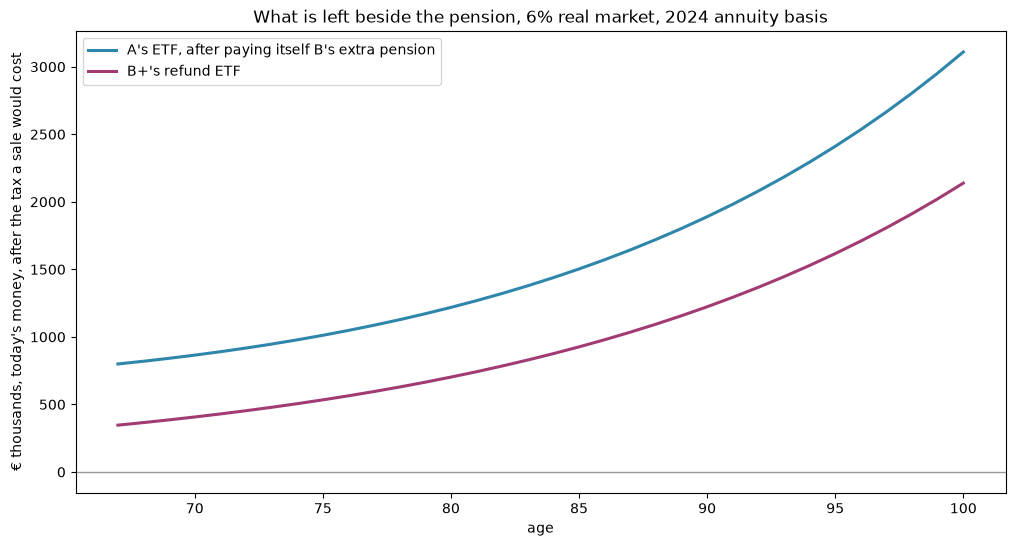

In [9]:
fig, ax = plt.subplots(figsize=(12, 6))
years = list(range(AT_67, YEARS + 1))
ages = [START_AGE + year for year in years]
ax.plot(ages, [todays(left[year], year) / 1000 for year in years], color="#2E86AB", lw=2.2, label="A's ETF, after paying itself B's extra pension")
ax.plot(ages, [todays(B_PLUS.loc[year, "refund_etf.capital_after_tax"], year) / 1000 for year in years], color="#A23B72", lw=2.2, label="B+'s refund ETF")
ax.axhline(0, color="#999999", lw=1)
ax.set_title(f"What is left beside the pension, {REAL_MARKET:.0%} real market, 2024 annuity basis")
ax.set_xlabel("age")
ax.set_ylabel("€ thousands, today's money, after the tax a sale would cost")
ax.legend()
plt.show()

The same across market returns: A's ETF at 67 against the contract's
capital, the pensions it buys, and how long A's ETF lasts when it pays out
B's extra net income — at the 2024 basis and at the guaranteed factor.

In [10]:
rows = []
for real in REAL_MARKETS:
    market = nominal(real)
    ws, gs = worlds_at(market), worlds_at(market, GUARANTEED)
    a, b, b_plus = ws["A"], ws["B"], ws["B+"]
    capital = b.loc[AT_67, "ruerup.pension_capital"]
    runs_out, behind, _ = verdicts(ws, market)
    runs_out_g, behind_g, _ = verdicts(gs, market)
    rows.append(
        {
            "market return, real": f"{real:.0%}",
            "A: ETF after tax at 67 (capital)": td(after_tax(a, "etf", AT_67), AT_67),
            "B: contract capital at 67 (capital)": td(capital, AT_67),
            "B+: refund ETF after tax at 67 (capital)": td(after_tax(b_plus, "refund_etf", AT_67), AT_67),
            "B's extra net income, 2024 basis, a month": td(pensions_net(b, AT_67 + 1) - pensions_net(a, AT_67 + 1), AT_67 + 1),
            "  the same, guaranteed, a month": td(pensions_net(gs["B"], AT_67 + 1) - pensions_net(a, AT_67 + 1), AT_67 + 1),
            "A's ETF runs out, 2024 basis": age(runs_out),
            "A's ETF falls behind B+, 2024 basis": age(behind),
            "A's ETF runs out, guaranteed": age(runs_out_g),
            "A's ETF falls behind B+, guaranteed": age(behind_g),
        }
    )
pd.DataFrame(rows).set_index("market return, real").T

"market return, real",3%,4%,6%,8%
A: ETF after tax at 67 (capital),"€396,845","€496,698","€799,554","€1,324,116"
B: contract capital at 67 (capital),"€355,277","€446,430","€719,047","€1,183,410"
B+: refund ETF after tax at 67 (capital),"€176,515","€219,087","€346,475","€563,277"
"B's extra net income, 2024 basis, a month",€988,"€1,231","€1,928","€3,020"
"the same, guaranteed, a month",€526,€658,"€1,045","€1,678"
"A's ETF runs out, 2024 basis",after 100,after 100,after 100,after 100
"A's ETF falls behind B+, 2024 basis",after 100,after 100,after 100,after 100
"A's ETF runs out, guaranteed",after 100,after 100,after 100,after 100
"A's ETF falls behind B+, guaranteed",after 100,after 100,after 100,after 100


A's ETF pays B's extra income and never runs out. At 6% real it earns 5.8%
a year on itself and pays out 2.9% of itself in the first year; the payout,
flat in nominal euros like the pension it matches, shrinks 2% a year in
today's money while the ETF compounds, so after paying B's pension for 33
years A still holds 3.1 million in today's money at 100 — more than B+'s
refund ETF at every age. The same holds at 3%, 4% and 8% and at both annuity
bases: a 750 € ETF buys B's pension and keeps the capital. What it does not
buy is certainty. A's payouts depend on the market delivering its 6% real
for seventy years, in order; B's do not depend on anything but the insurer.
That difference is the whole price of the contract, and at these returns the
price is the capital.

## 5. Year by Year at the Base Market Return

In today's euros: the tax the contract saves, a month (it arrives the next
July as one sum, spent in B and invested in B+), the contract value, the
pension once it runs, and the two ETFs after tax. From November 2063 the
value is a pension and the contract value reads zero.

In [11]:
saved = A["household.yearly_assessed_tax"] - B["household.yearly_assessed_tax"]
rows = []
for year in (1, 2, 5, 10, 20, 30, 38, 39, 45, 55, 65, YEARS):
    row = B.loc[year]
    rows.append(
        {
            "year": f"{year} ({2025 + year}), age {int(row['age'])}",
            "tax saved, a month": td(saved[year] / 12.0, year) if year <= AT_67 else "",
            "contract value (capital)": td(row["ruerup.contract_value"], year),
            "pension, a month": td(row["ruerup.monthly_pension"], year) if row["ruerup.monthly_pension"] > 0.0 else "",
            "A's ETF after tax (capital)": td(A.loc[year, "etf.capital_after_tax"], year),
            "B+'s refund ETF after tax (capital)": td(B_PLUS.loc[year, "refund_etf.capital_after_tax"], year),
        }
    )
pd.DataFrame(rows).set_index("year")

,"tax saved, a month",contract value (capital),"pension, a month",A's ETF after tax (capital),B+'s refund ETF after tax (capital)
year,,,,,
"1 (2026), age 30",€346,"€6,980",,"€9,081",€0
"2 (2027), age 31",€339,"€14,184",,"€18,382","€4,172"
"5 (2030), age 34",€319,"€37,290",,"€47,834","€17,338"
"10 (2035), age 39",€289,"€90,109",,"€103,545","€42,088"
"20 (2045), age 49",€237,"€232,897",,"€253,955","€108,292"
"30 (2055), age 59",€195,"€454,375",,"€494,551","€213,407"
"38 (2063), age 67",€-90,€0,"€2,918","€799,554","€346,475"
"39 (2064), age 68",,€0,"€2,861","€843,537","€365,475"
"45 (2070), age 74",,€0,"€2,540","€1,167,370","€505,391"


## 6. A Third Way: the Altersvorsorgedepot, at 150 € a Month

Trade Republic's Altersvorsorgedepot, as modelled here: the same ETF, held
in a depot whose contributions are deducted like a Basisrente's, with none
of the insurer's costs, and whose capital at 67 stays yours — paid out at a
pace you choose and taxed in full as income when it is paid, the way the
Basisrente's pension is. The sum is 150 € a month, and the question is asked
three ways plus one:

1. **150 € into the plain ETF**, taxed on its gain at sale.
2. **150 € into the depot**, the refund spent: 70 € a month comes back, so
   the net cost is 80 €.
3. **283 € into the depot**, the refund spent: 133 € comes back, the net cost
   is the same 150 € as in the ETF — the same money.
4. **283 € into the Basisrente**, the refund spent, the net cost 150 € — the
   contract priced against the depot, euro for euro.

The depot's capital is paid out from November 2063 under the same three
rules as the ETF's — 3% or 4% a year of the capital at the start, flat in
nominal euros, or a level drawdown to 100 — and the engine taxes each year's
payouts on top of the statutory pension. The ETF's payouts are taxed on
their gain share, outside the engine, as in section 3.

In [12]:
from src.model import Cardinality, CashFlow, CashPhase, FinancialComponent


@dataclass(slots=True)
class DepotState:
    value: float
    month: int
    monthly_rate: float
    payout: float = 0.0          # the fixed monthly payout, once it starts
    current: float = 0.0         # this month's payout
    capital_at_start: float = 0.0
    year_contributions: float = 0.0
    year_payout: float = 0.0


@dataclass(frozen=True)
class Depot(FinancialComponent):
    # An Altersvorsorgedepot as described above: contributions deducted like
    # a Basisrente's (published through the same channel), invested at the
    # ETF's return with no costs, paid out from the month after the last
    # contribution and published as taxable pension income. `payout_months`
    # > 0 is a level drawdown over that many months; otherwise `payout_rate`
    # of the capital at the start is paid a year, flat in nominal euros.
    default_name = "depot"
    cardinality = Cardinality.MULTI
    report_kind = "pension"
    absorbs_cash = True

    monthly_contribution: float = 0.0
    contribution_months: int = 0
    yearly_return_rate: float = 0.0
    payout_rate: float = 0.0
    payout_months: int = 0
    name: str | None = None

    @property
    def produces_taxable_income(self) -> bool:
        return True

    def open(self, ctx) -> DepotState:
        return DepotState(value=0.0, month=0, monthly_rate=(1.0 + self.yearly_return_rate) ** (1.0 / 12.0) - 1.0)

    def year_begin(self, state, ctx):
        state.year_contributions = 0.0
        state.year_payout = 0.0

    def month_begin(self, state, ctx):
        state.month += 1
        if state.month <= self.contribution_months:
            return
        grown = state.value * (1.0 + state.monthly_rate)
        if state.month == self.contribution_months + 1:
            state.capital_at_start = grown
            if self.payout_months > 0:
                rate = state.monthly_rate
                state.payout = grown * rate / (1.0 - (1.0 + rate) ** -self.payout_months)
            else:
                state.payout = grown * self.payout_rate / 12.0
        state.current = min(state.payout, grown)
        state.value = grown - state.current
        state.year_payout += state.current

    def cash_flows(self, state, ctx):
        if state.month > self.contribution_months and state.current > 0.0:
            return (CashFlow(CashPhase.PENSION, state.current),)
        return ()

    def claim(self, state, ctx):
        return self.monthly_contribution if state.month <= self.contribution_months else 0.0

    def absorb(self, state, ctx, amount):
        if state.month > self.contribution_months:
            return
        state.value = state.value * (1.0 + state.monthly_rate) + amount
        state.year_contributions += amount

    def year_settle(self, state, ctx):
        if state.year_contributions > 0.0:
            ctx.add_basisrente_contribution(state.year_contributions)
        if state.year_payout > 0.0:
            ctx.add_pension_income(state.year_payout)

    def report(self, state, ctx):
        return self._report(state)

    def report_initial(self, state):
        return self._report(state)

    def _report(self, state):
        return {
            "value": state.value,
            "capital_at_start": state.capital_at_start,
            "monthly_payout": state.current,
            "yearly_contributions": state.year_contributions,
            "yearly_payout": state.year_payout,
        }


SMALL = 150.0
RULES = {"3% a year": dict(payout_rate=0.03), "4% a year": dict(payout_rate=0.04), "drawn down to 100": dict(payout_months=33 * 12)}


def depot(amount: float, rule: dict, market: float = MARKET) -> Depot:
    return Depot(monthly_contribution=amount, contribution_months=WORKING_MONTHS,
                 yearly_return_rate=fund_return(market, ETF_TER), name="depot", **rule)


def small_basisrente(amount: float, annuity: RuerupAnnuity = DECLARED, market: float = MARKET) -> RuerupPension:
    return RuerupPension(monthly_contribution=amount, contribution_months=WORKING_MONTHS,
                         yearly_return_rate=fund_return(market, FUND_COSTS), annuity=annuity, name="ruerup")


# The gross contribution that nets to SMALL after the refund at the 2026 marginal rate.
probe = run(small_basisrente(SMALL), market=MARKET)
plain = run(etf(MARKET, every_month(SMALL, WORKING_MONTHS)), market=MARKET)
refund_rate = (plain.loc[1, "household.yearly_assessed_tax"] - probe.loc[1, "household.yearly_assessed_tax"]) / (12.0 * SMALL)
GROSSED_UP = round(SMALL / (1.0 - refund_rate))
print(f"Refund rate on the first euro: {refund_rate:.1%}; a net {SMALL:,.0f} € a month is {GROSSED_UP:,} € gross")

variants = {
    f"1) ETF, {SMALL:,.0f} €": dict(kind="etf", amount=SMALL),
    f"2) depot, {SMALL:,.0f} €": dict(kind="depot", amount=SMALL),
    f"3) depot, {GROSSED_UP:,} € (net {SMALL:,.0f})": dict(kind="depot", amount=float(GROSSED_UP)),
    f"4) Basisrente, {GROSSED_UP:,} € (net {SMALL:,.0f})": dict(kind="ruerup", amount=float(GROSSED_UP)),
}

Refund rate on the first euro: 47.0%; a net 150 € a month is 283 € gross


In [13]:
def income(frame: pd.DataFrame, year: int) -> float:
    # The month's net income: pensions and payouts after premiums and the year's income tax.
    extra = 0.0
    for column in ("ruerup.monthly_pension", "depot.monthly_payout"):
        if column in frame:
            extra += frame[column][year]
    return frame.loc[year, "household.monthly_amount"] + extra - frame.loc[year, "household.yearly_assessed_tax"] / 12.0


base_income = income(plain, YEAR)   # the statutory pension alone, net: the same in every variant
table = {}
runs = {}
for label, spec in variants.items():
    column = {}
    if spec["kind"] == "etf":
        frame = run(etf(MARKET, every_month(spec["amount"], WORKING_MONTHS)), market=MARKET)
        runs[label] = frame
        capital = after_tax(frame, "etf", AT_67)
        column["capital at 67 (capital)"] = td(capital, AT_67) + " after tax"
        for rule in RULES:
            if rule == "drawn down to 100":
                payout = drawdown(after_tax(frame, "etf", YEAR - 1))
            else:
                payout = after_tax(frame, "etf", YEAR - 1) * float(rule[:1]) / 100.0 / 12.0
            column[f"{rule}: payout net"] = td(payout, YEAR)
            column[f"{rule}: total net income"] = td(base_income + payout, YEAR)
        refund = 0.0
    elif spec["kind"] == "depot":
        frames = {rule: run(depot(spec["amount"], params), market=MARKET) for rule, params in RULES.items()}
        runs[label] = frames
        first = next(iter(frames.values()))
        column["capital at 67 (capital)"] = td(first.loc[AT_67, "depot.capital_at_start"], AT_67) + " before tax"
        for rule, frame in frames.items():
            column[f"{rule}: payout net"] = td(income(frame, YEAR) - base_income, YEAR)
            column[f"{rule}: total net income"] = td(income(frame, YEAR), YEAR)
        refund = sum(max(float(first.loc[y, "household.yearly_refund_received"] - plain.loc[y, "household.yearly_refund_received"]), 0.0) for y in range(2, AT_67 + 2))
    else:
        frame = run(small_basisrente(spec["amount"]), market=MARKET)
        frame_g = run(small_basisrente(spec["amount"], GUARANTEED), market=MARKET)
        runs[label] = (frame, frame_g)
        column["capital at 67 (capital)"] = td(frame.loc[AT_67, "ruerup.pension_capital"], AT_67) + " converted"
        net = income(frame, YEAR) - base_income
        for rule in RULES:
            column[f"{rule}: payout net"] = td(net, YEAR) + " (pension)"
            column[f"{rule}: total net income"] = td(income(frame, YEAR), YEAR)
        column["guaranteed factor: pension net"] = td(income(frame_g, YEAR) - base_income, YEAR)
        refund = sum(max(float(frame.loc[y, "household.yearly_refund_received"] - plain.loc[y, "household.yearly_refund_received"]), 0.0) for y in range(2, AT_67 + 2))
    column["contribution, gross"] = f"€{spec['amount']:,.0f} a month"
    column["refund, spent"] = f"€{refund / (12.0 * 37):,.0f} a month on average" if refund else "€0"
    column["net cost"] = f"€{spec['amount'] - refund / (12.0 * 37):,.0f} a month"
    table[label] = column
order = ["contribution, gross", "refund, spent", "net cost", "capital at 67 (capital)"]
for rule in RULES:
    order += [f"{rule}: payout net", f"{rule}: total net income"]
order += ["guaranteed factor: pension net"]
print(f"Statutory pension alone, net, in 2064: {td(base_income, YEAR)} a month — the base every total starts from")
pd.DataFrame(table).reindex(order).fillna("")

Statutory pension alone, net, in 2064: €2,238 a month — the base every total starts from


,"1) ETF, 150 €","2) depot, 150 €","3) depot, 283 € (net 150)","4) Basisrente, 283 € (net 150)"
"contribution, gross",€150 a month,€150 a month,€283 a month,€283 a month
"refund, spent",€0,€70 a month on average,€133 a month on average,€133 a month on average
net cost,€150 a month,€80 a month,€150 a month,€150 a month
capital at 67 (capital),"€159,911 after tax","€187,660 before tax","€354,052 before tax","€271,320 converted"
3% a year: payout net,€392,€329,€615,€761 (pension)
3% a year: total net income,"€2,630","€2,568","€2,853","€2,999"
4% a year: payout net,€523,€437,€814,€761 (pension)
4% a year: total net income,"€2,761","€2,676","€3,053","€2,999"
drawn down to 100: payout net,"€1,124",€894,"€1,638",€761 (pension)
drawn down to 100: total net income,"€3,362","€3,132","€3,877","€2,999"


The table above taxes the depot's payouts and the contract's pension at the
engine's own progressive rate for a retiree with the maximum statutory
pension and nothing else: about 30 cents on the euro. That rate is the least
certain input, so here are the same payouts under four tax rates on the
pension income: a small one, the engine's own, the 42% zone with Soli (where
a 100,000 € salary sits today) and the top of the tariff. The ETF's gain is
taxed at 18.46% whatever the income — except at the small rate, where the
Günstigerprüfung taxes the gain at the personal rate instead, 15% with Soli
on 70% of it. Net payouts a month in 2064, today's euros, before the
statutory pension.

In [14]:
RATES = {
    "15% (a small pension)": 0.15,
    "engine's own: ~30%": None,
    "44.3% (42% + Soli, a 100k salary today)": 0.42 * 1.055,
    "47.5% (45% + Soli, the top)": 0.45 * 1.055,
}
labels = list(variants)
etf_label, ruerup_label = labels[0], labels[3]
etf_frame = runs[etf_label]
etf_gross, etf_basis = etf_frame.loc[YEAR - 1, "etf.capital"], etf_frame.loc[YEAR - 1, "etf.cost_basis"]
ruerup_frame, ruerup_guaranteed = runs[ruerup_label]

rows = []
for rate_label, tax_rate in RATES.items():
    for rule in RULES:
        row = {"tax on pension income": rate_label, "payout rule": rule}
        # the ETF: its gain taxed at 18.46%, or at the personal rate when that is lower
        gain_tax = min(ETF_TAX, tax_rate * 1.055 * 0.7) if tax_rate is not None else ETF_TAX
        etf_net_capital = etf_gross - (etf_gross - etf_basis) * gain_tax
        etf_payout = drawdown(etf_net_capital) if rule == "drawn down to 100" else etf_net_capital * float(rule[:1]) / 100.0 / 12.0
        row[etf_label] = td(etf_payout, YEAR)
        for label in labels[1:3]:
            frame = runs[label][rule]
            gross = frame.loc[YEAR, "depot.monthly_payout"]
            row[label] = td(income(frame, YEAR) - base_income, YEAR) if tax_rate is None else td(gross * (1.0 - tax_rate), YEAR)
        pension = ruerup_frame.loc[YEAR, "ruerup.monthly_pension"]
        pension_g = ruerup_guaranteed.loc[YEAR, "ruerup.monthly_pension"]
        if tax_rate is None:
            row[ruerup_label] = td(income(ruerup_frame, YEAR) - base_income, YEAR)
            row["4) Basisrente, guaranteed factor"] = td(income(ruerup_guaranteed, YEAR) - base_income, YEAR)
        else:
            row[ruerup_label] = td(pension * (1.0 - tax_rate), YEAR)
            row["4) Basisrente, guaranteed factor"] = td(pension_g * (1.0 - tax_rate), YEAR)
        rows.append(row)
pd.DataFrame(rows).set_index(["tax on pension income", "payout rule"])

1) ETF, 150 €  \
tax on pension income                   payout rule                       
15% (a small pension)                   3% a year                  €420   
                                        4% a year                  €560   
                                        drawn down to 100        €1,205   
engine's own: ~30%                      3% a year                  €392   
                                        4% a year                  €523   
                                        drawn down to 100        €1,124   
44.3% (42% + Soli, a 100k salary today) 3% a year                  €392   
                                        4% a year                  €523   
                                        drawn down to 100        €1,124   
47.5% (45% + Soli, the top)             3% a year                  €392   
                                        4% a year                  €523   
                                        drawn down to 100        €1,124   

                                                          2) depot, 150 €  \
tax on pension income                   payout rule                         
15% (a small pension)                   3% a year                    €391   
                                        4% a year                    €521   
                                        drawn down to 100          €1,082   
engine's own: ~30%                      3% a year                    €329   
                                        4% a year                    €437   
                                        drawn down to 100            €894   
44.3% (42% + Soli, a 100k salary today) 3% a year                    €256   
                                        4% a year                    €342   
                                        drawn down to 100            €709   
47.5% (45% + Soli, the top)             3% a year                    €242   
                                        4% a year                    €322   
                                        drawn down to 100            €669   

                                                          3) depot, 283 € (net 150)  \
tax on pension income                   payout rule                                   
15% (a small pension)                   3% a year                              €738   
                                        4% a year                              €983   
                                        drawn down to 100                    €2,042   
engine's own: ~30%                      3% a year                              €615   
                                        4% a year                              €814   
                                        drawn down to 100                    €1,638   
44.3% (42% + Soli, a 100k salary today) 3% a year                              €483   
                                        4% a year                              €644   
                                        drawn down to 100                    €1,338   
47.5% (45% + Soli, the top)             3% a year                              €456   
                                        4% a year                              €608   
                                        drawn down to 100                    €1,262   

                                                          4) Basisrente, 283 € (net 150)  \
tax on pension income                   payout rule                                        
15% (a small pension)                   3% a year                                   €918   
                                        4% a year                                   €918   
                                        drawn down to 100                           €918   
engine's own: ~30%                      3% a year                                   €761   
                                        4% a year                                   €761   
                                        drawn down to 100        

Three things the table says. First, the deduction is worth having only when
it is used: 150 € in the depot with the refund spent (variant 2) ends below
150 € in the plain ETF — a smaller capital, then 30% income tax on every
payout against 18% on the ETF's gain. Second, the same 150 € net put into
the depot grossed up to 283 € (variant 3) beats the plain ETF by about half
at every payout rule: 615 € against 392 € at 3%, 814 € against 523 € at 4%,
1,638 € against 1,124 € drawn down — deduct at 47 cents, pay back 30 cents
on the whole, and no costs in between. Third, the Basisrente at the same
283 € (variant 4) pays 761 € for life, between the depot's 3% and 4% rules,
but the depot keeps its 354,000 € where the contract's 271,000 € — the
insurer's costs having taken the difference — are gone into the annuity;
at the guaranteed factor the pension is 404 €. At these returns the depot
dominates the contract: the same tax treatment, no costs, the capital still
yours. What the depot does not give is the lifelong guarantee, and what it
cannot be given here is its real rulebook — the cap on subsidised
contributions, the Zulagen, the payout rules from the law — which this
section replaces with "deducted like a Basisrente" as asked.

## 7. Depot Against Basisrente, Factor by Factor

The same 283 € a month, the same deduction, the same market, the same tax on
the way out: what separates the depot from the contract is a short list, and
each item can be switched off in the model to see what it is worth. Two
stages, because the products differ in two places.

**On the way to 67** the contract charges four things the depot does not:
the acquisition cost (2.5% of the contribution sum, over the first five
years), 4.5% of every contribution, 0.40% a year on the value, and funds
that cost 0.38% a year where the ETF costs 0.20%. Switching them off one at
a time turns the contract's capital into the depot's; the order changes the
shares a little, so they are also given as Shapley values, the average over
every order.

**From 67 on** the contract converts its capital into a lifelong pension at
the insurer's factor — 4.87% of the capital a year at the 2024 basis, 2.55%
guaranteed — while the depot pays out at whatever rate is chosen and keeps
the rest. At the same capital this is the only remaining difference, since
the engine taxes the depot's payouts and the pension alike: fully, as
income, on top of the statutory pension. The tax on the way in is identical
too — the refunds are compared below to the cent.

In [15]:
from itertools import permutations

AMOUNT_7 = float(GROSSED_UP)
FACTORS = [
    ("acquisition cost: 2.5% of the contribution sum", "acquisition"),
    ("4.5% of every contribution", "contribution"),
    ("0.40% a year on the value", "capital_charge"),
    ("fund costs 0.38% a year, against the ETF's 0.20%", "fund_costs"),
]
CONTRACT = dict(acquisition=0.025, contribution=0.045, capital_charge=0.004, fund_costs=FUND_COSTS)
NONE = dict(acquisition=0.0, contribution=0.0, capital_charge=0.0, fund_costs=ETF_TER)


def capital_with_costs(acquisition: float, contribution: float, capital_charge: float, fund_costs: float) -> float:
    return RuerupPension(
        monthly_contribution=AMOUNT_7,
        contribution_months=WORKING_MONTHS,
        yearly_return_rate=fund_return(MARKET, fund_costs),
        costs=RuerupCosts(acquisition_rate=acquisition, acquisition_months=60, contribution_rate=contribution, capital_rate=capital_charge),
    ).capital_at_pension_start()


start, end = capital_with_costs(**CONTRACT), capital_with_costs(**NONE)
depot_capital = runs[labels[2]]["4% a year"].loc[AT_67, "depot.capital_at_start"]
assert abs(end - depot_capital) < 1.0, "with every cost switched off the contract is the depot"
gap = end - start

# One order: the natural one. Every order: Shapley.
shapley = {key: 0.0 for _, key in FACTORS}
orders = list(permutations([key for _, key in FACTORS]))
for order_ in orders:
    settings, value = dict(CONTRACT), start
    for key in order_:
        settings[key] = NONE[key]
        new = capital_with_costs(**settings)
        shapley[key] += (new - value) / len(orders)
        value = new

rows = [{"": "the contract as it is", "capital at 67 (capital)": td(start, AT_67), "this factor adds (capital)": "", "share, this order": "", "share, Shapley": ""}]
settings, value = dict(CONTRACT), start
for label, key in FACTORS:
    settings[key] = NONE[key]
    new = capital_with_costs(**settings)
    rows.append({
        "": f"without the {label}",
        "capital at 67 (capital)": td(new, AT_67),
        "this factor adds (capital)": td(new - value, AT_67),
        "share, this order": f"{(new - value) / gap:.0%}",
        "share, Shapley": f"{shapley[key] / gap:.0%}",
    })
    value = new
rows.append({"": "= the depot", "capital at 67 (capital)": td(end, AT_67), "this factor adds (capital)": td(gap, AT_67), "share, this order": "100%", "share, Shapley": "100%"})
print(f"The contract's capital is {start / end:.1%} of the depot's; the costs take {td(gap, AT_67)} of today's money by 67")
pd.DataFrame(rows).set_index("")

The contract's capital is 76.6% of the depot's; the costs take €82,732 of today's money by 67


,capital at 67 (capital),this factor adds (capital),"share, this order","share, Shapley"
,,,,
the contract as it is,"€271,320",,,
without the acquisition cost: 2.5% of the contribution sum,"€289,594","€18,274",22%,25%
without the 4.5% of every contribution,"€303,240","€13,646",16%,18%
without the 0.40% a year on the value,"€337,264","€34,025",41%,40%
"without the fund costs 0.38% a year, against the ETF's 0.20%","€354,052","€16,788",20%,18%
= the depot,"€354,052","€82,732",100%,100%


**The tax on the way in.** Both deduct the same 3,396 € a year, so the
refunds must be the same. The engine's own figures, world against world:

In [16]:
depot_frame = runs[labels[2]]["4% a year"]
ruerup_frame, ruerup_guaranteed = runs[labels[3]]
saved_depot = plain["household.yearly_assessed_tax"] - depot_frame["household.yearly_assessed_tax"]
saved_ruerup = plain["household.yearly_assessed_tax"] - ruerup_frame["household.yearly_assessed_tax"]
through_2062 = (saved_depot.loc[1:AT_67 - 1].sum(), saved_ruerup.loc[1:AT_67 - 1].sum())
print(f"tax saved 2026–2062: depot {eur(through_2062[0])}, contract {eur(through_2062[1])}, difference {eur(through_2062[0] - through_2062[1])}")
print(f"2063, the year with ten contributions and two payout months: depot {eur(saved_depot[AT_67])}, contract {eur(saved_ruerup[AT_67])} "
      f"— the two months' payouts differ, nothing else does")

tax saved 2026–2062: depot €58,969, contract €58,969, difference €0
2063, the year with ten contributions and two payout months: depot €-1,025, contract €-867 — the two months' payouts differ, nothing else does


**From 67 on.** The payout stage at the engine's tax rate: the contract at
both annuity bases, and the depot under its three rules plus two more that
copy the contract's own conversion rates — 4.87% and 2.55% of the capital a
year, flat in nominal euros. With the rate copied, the whole difference in
the payout is the capital, and the difference in what is left afterwards is
the product: the depot keeps its capital, the contract has handed it over.
A month in 2064, in today's euros, capital in today's euros too.

In [17]:
declared_rate = DECLARED.factor * 12.0 / 10_000.0 + DECLARED.bonus_rate
guaranteed_rate = GUARANTEED.factor * 12.0 / 10_000.0
payout_rules = dict(RULES)
payout_rules[f"{declared_rate:.2%} a year: the contract's 2024 basis"] = dict(payout_rate=declared_rate)
payout_rules[f"{guaranteed_rate:.2%} a year: the contract's guaranteed factor"] = dict(payout_rate=guaranteed_rate)
depot_runs = {rule: runs[labels[2]][rule] if rule in RULES else run(depot(AMOUNT_7, params), market=MARKET) for rule, params in payout_rules.items()}


def payout_row(label: str, frame: pd.DataFrame, gross_column: str, residual_column: str | None) -> dict:
    gross = frame.loc[YEAR, gross_column]
    net = income(frame, YEAR) - base_income
    row = {
        "": label,
        "gross, a month": td(gross, YEAR),
        "tax on it": f"{1.0 - net / gross:.1%}",
        "net, a month": td(net, YEAR),
    }
    for year, label_year in ((AT_67 + 13, "left at 80 (capital)"), (AT_67 + 23, "left at 90 (capital)"), (YEARS, "left at 100 (capital)")):
        row[label_year] = td(frame.loc[year, residual_column], year) if residual_column else "€0"
    return row


rows = [
    payout_row("contract, 2024 basis", ruerup_frame, "ruerup.monthly_pension", None),
    payout_row("contract, guaranteed factor", ruerup_guaranteed, "ruerup.monthly_pension", None),
]
for rule, frame in depot_runs.items():
    rows.append(payout_row(f"depot, {rule}", frame, "depot.monthly_payout", "depot.value"))
pd.DataFrame(rows).set_index("")

,"gross, a month",tax on it,"net, a month",left at 80 (capital),left at 90 (capital),left at 100 (capital)
,,,,,,
"contract, 2024 basis","€1,079",29.5%,€761,€0,€0,€0
"contract, guaranteed factor",€565,28.6%,€404,€0,€0,€0
"depot, 3% a year",€868,29.1%,€615,"€555,102","€873,796","€1,451,290"
"depot, 4% a year","€1,157",29.6%,€814,"€493,321","€731,814","€1,174,551"
"depot, drawn down to 100","€2,403",31.8%,"€1,638","€227,295","€120,448",€0
"depot, 4.87% a year: the contract's 2024 basis","€1,409",30.1%,€985,"€439,599","€608,353","€933,912"
"depot, 2.55% a year: the contract's guaranteed factor",€737,28.9%,€525,"€582,927","€937,743","€1,575,928"


**The shares.** For each of the depot's rules, the net payout's difference
to the contract's pension at the 2024 basis, split into what the capital
explains (the depot paid out at the contract's own 4.87%, against the
contract) and what the rule explains (the depot at its rule, against the
depot at 4.87%). The two add up exactly to the difference, up to the few
euros by which the progressive tax rate moves with the amount.

In [18]:
contract_net = income(ruerup_frame, YEAR) - base_income
copied = next(rule for rule in depot_runs if "2024 basis" in rule)
depot_same_rate = income(depot_runs[copied], YEAR) - base_income
rows = []
for rule in RULES:
    net = income(depot_runs[rule], YEAR) - base_income
    total = net - contract_net
    capital_effect = depot_same_rate - contract_net
    rate_effect = net - depot_same_rate
    rows.append({
        "depot rule": rule,
        "depot net, a month": td(net, YEAR),
        "contract net, a month": td(contract_net, YEAR),
        "difference, a month": f"{todays(total, YEAR):+,.0f}",
        "of which the capital (costs)": f"{todays(capital_effect, YEAR):+,.0f}",
        "of which the payout rate": f"{todays(rate_effect, YEAR):+,.0f}",
        "taxation": "the same",
    })
pd.DataFrame(rows).set_index("depot rule")

,"depot net, a month","contract net, a month","difference, a month",of which the capital (costs),of which the payout rate,taxation
depot rule,,,,,,
3% a year,€615,€761,-146,+224,-370,the same
4% a year,€814,€761,+53,+224,-171,the same
drawn down to 100,"€1,638",€761,+877,+224,+653,the same


**What the factors are worth.** On the way to 67 the contract's four
charges cost 82,700 € of today's money, 23% of the depot's 354,000 €. The
0.40% a year on the value is the largest of them, two fifths of the gap: it
compounds for 38 years. The acquisition cost is a quarter — small in euros
(8,500 € spread over five years) but taken first, when every euro has the
longest to grow. The 4.5% of every contribution and the funds' extra 0.18% a
year are a fifth each. The deduction is worth exactly the same in both
products: the refunds agree to the euro through 2062.

From 67 on the contract pays out faster than any cautious rule — 4.87% of
its capital a year at the 2024 basis, against 3% or 4% — and that is the one
factor in its favour on the monthly cheque: at the 4% rule it is worth 171 €
a month to the contract, at 3% 370 €. The capital it lost to its costs is
worth 224 € a month against it. Net, the depot pays 146 € less a month at
3%, 53 € more at 4%, 877 € more drawn down to 100. But the rule that makes
the contract's cheque larger is the one that leaves it nothing: the depot at
the contract's own 4.87% still holds 934,000 € of today's money at 100, at
4% 1.2 million, where the contract holds nothing at any age. Taxation
explains none of the difference: both are deducted alike and both payouts
are taxed alike, at 29 to 32 cents on the euro depending only on the amount.

Two things the table cannot show. The 4.87% is not promised: at the
guaranteed factor the contract pays 2.55%, 404 € net, and the depot wins
every comparison outright. And the contract pays until death, however long
that is, while the depot's capital, large as it stays here, is a number in a
smooth-return model — the one thing the contract sells is what the engine
cannot price.

## What This Leaves Out

- The contract you actually hold — 500 € a month since November 2024 — is in
  no world. Put into all of them, it would tax this pension harder (it is
  already in the zvE) and leave only 519 € a month of deduction room in 2026,
  so a 750 € contract on top would be partly non-deductible until 2033.
- A's payouts in section 4 are flat in nominal euros, like the pension they
  match, and A keeps selling until the ETF is gone; a real retiree would
  adjust. The 3% and drawdown rows in section 3 are the other two readings.
- No Rentengarantiezeit: a death before 87 would pay the remaining guaranteed
  months to the heirs, while A's ETF goes to them whole.
- The pension stays flat in nominal euros, as the tariff has it; above a 3%
  Gesamtverzinsung the insurer would raise it a little each year. The
  guaranteed factor and the 2024 basis bracket what it may be at 67; neither
  is a forecast.
- Returns are smooth, and the same for both products. With volatile ones the
  kursorientiertes Ablaufmanagement in the contract would matter, and so
  would the order of good and bad years — the one thing a lifelong pension
  insures against that the engine cannot price.
- The Finanzamt only reads the last assessment: the first retired year's tax
  is one back-payment the July after, paid out of that month's cash.
- Your private premium rises at 3.5% a year for life; the drop at 65, when
  the statutory 10% surcharge stops, is not modelled.
- The statutory pension sets the tax rate on the Rürup pension: 80 points is
  the ceiling, a smaller pension would tax it more lightly. A spouse, a
  second salary, children are left out on purpose; they would change the
  deduction room and the tax rates in working life and old age.